In [6]:
import os
root = "/kaggle/input"
for dirpath, dirnames, filenames in os.walk(root):
    depth = dirpath.replace(root, "").count(os.sep)
    if depth > 5:
        continue
    print("  " * depth + os.path.basename(dirpath) + f"/   [{len(filenames)} files]")

input/   [0 files]
  datasets/   [0 files]
    xhlulu/   [0 files]
      140k-real-and-fake-faces/   [3 files]
        real_vs_fake/   [0 files]
          real-vs-fake/   [0 files]
  notebooks/   [0 files]
    paulopinheiro/   [0 files]


In [7]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATA = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake"

tf = transforms.Compose([
    transforms.Resize((128, 128)),   # all images to a fixed size
    transforms.ToTensor(),           # -> tensor, pixels rescaled to 0.0-1.0
])

train_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf)
valid_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf)
test_ds  = datasets.ImageFolder(f"{DATA}/test",  transform=tf)

print("classes:", train_ds.classes)
print(f"train {len(train_ds):,}   valid {len(valid_ds):,}   test {len(test_ds):,}")

img, label = train_ds[0]
print("one image tensor:", img.shape, " label:", label, "=", train_ds.classes[label])

classes: ['fake', 'real']
train 100,000   valid 20,000   test 20,000
one image tensor: torch.Size([3, 128, 128])  label: 0 = fake


In [ ]:
import random
import matplotlib.pyplot as plt

fake_idx = [i for i, t in enumerate(train_ds.targets) if t == 0]
real_idx = [i for i, t in enumerate(train_ds.targets) if t == 1]

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for col in range(6):
    for row, idxs in enumerate([fake_idx, real_idx]):
        img, label = train_ds[random.choice(idxs)]
        axes[row, col].imshow(img.permute(1, 2, 0))
        axes[row, col].set_title(train_ds.classes[label])
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/sample_faces.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
valid_dl = DataLoader(valid_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

images, labels = next(iter(train_dl))
print("one batch:", images.shape, labels.shape)

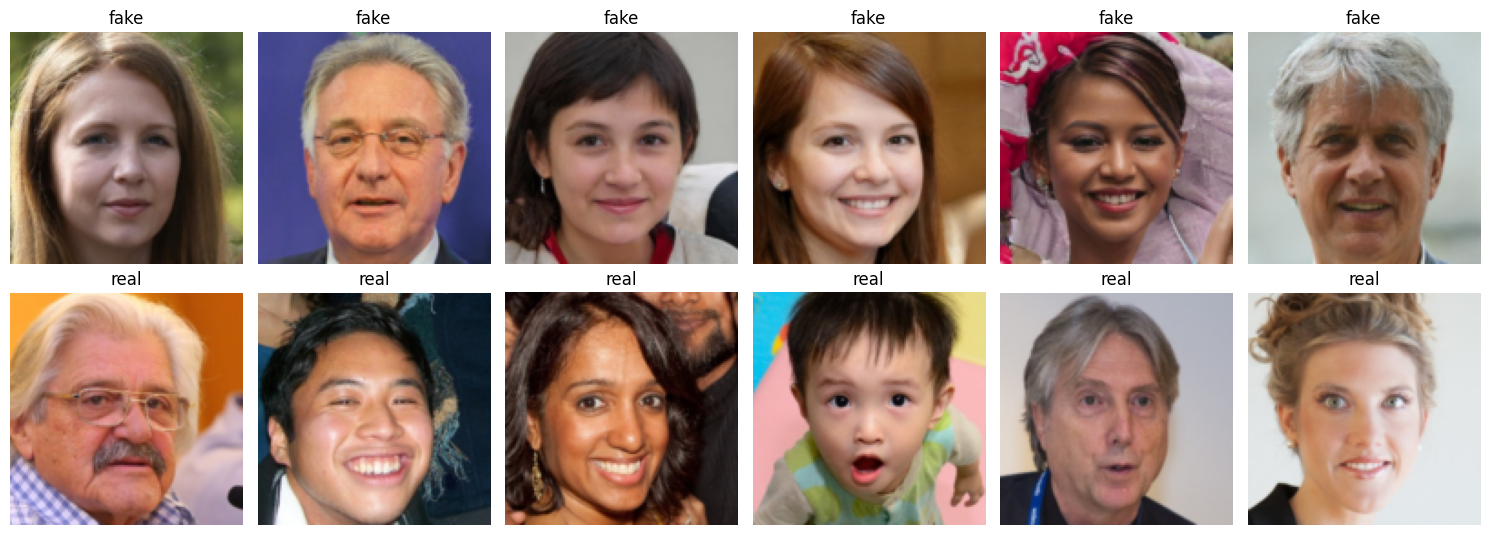

In [8]:
import random
import matplotlib.pyplot as plt

fake_idx = [i for i, t in enumerate(train_ds.targets) if t == 0]
real_idx = [i for i, t in enumerate(train_ds.targets) if t == 1]

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for col in range(6):
    for row, idxs in enumerate([fake_idx, real_idx]):
        img, label = train_ds[random.choice(idxs)]
        axes[row, col].imshow(img.permute(1, 2, 0))
        axes[row, col].set_title(train_ds.classes[label])
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/sample_faces.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
valid_dl = DataLoader(valid_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

images, labels = next(iter(train_dl))
print("one batch:", images.shape, labels.shape)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


one batch: torch.Size([128, 3, 128, 128]) torch.Size([128])
